# 34 — R2: is the diagnosis robust to uncertain inlet conditions? (System I)

**Why.** The jacket removes only ~19% of the reaction heat; the feed absorbs ~81%. The jacket
duty, and therefore β, is sensitive to the feed temperature: to first order a 1 K error in Ti
shifts the duty by ~27% (~0.2 in β). The generative model treats the inlet (Ci, Ti, Tci) as exactly
known, while the N3 production posterior reports β with sd ≈ 0.015. If realistic inlet errors bias
β by many posterior sds, the precision claim does not survive contact with a real plant. In the
paper's storyline this is the fourth source of silent failure (after the control law, the warm
start and the sensor model), or, if the posterior holds, evidence for the "reliable" half.

**A built-in alarm?** The production summary set S1 contains two independent plug-in estimates of
β: one from the jacket/coolant balance (uses Tci, Qc, Tc) and one from the reactor balance (uses
Ti, Ci). An error in Ti corrupts only the second, an error in Tci only the first, so their
disagreement d = ln β̂_jac − ln β̂_rx may flag inlet misspecification from the data alone.

**Design** (N3 sensors, P2 protocol, as production)
* **Check.** The per-sample-inlet simulator (`scripts/ws_inlet.py`) reproduces the production
  simulator at the nominal inlet to < 1% of the sensor σ; deterministic first-order sensitivity of
  the plug-in estimators to each inlet error.
* **Part A — misspecification.** True plant inlet perturbed one factor at a time: Ti ±0.5, ±1 K;
  Tci ±0.5, ±1 K; Ci ±1, ±2%. Scenarios Sc1–Sc5 × 50 windows with common random numbers. Posteriors
  (all assume the nominal inlet): the N3 production posterior (nb31) and, for S0 vs S1 at equal
  budget, the notebook 03 §10b ensembles at 20k.
* **Part B — robust training** (only if the rule below triggers, or `FORCE_B`). S1 posteriors at
  40k × 3 seeds, trained with the inlet fixed ("nominal") or drawn per sample as a nuisance
  ("robust": Ti, Tci ~ N(297, 0.5²) K, Ci ± 1% sd); compared on the Part A conditions and on SBC
  sets under both inlet distributions. Part B reports; it does not change production.

## Decision rule — fixed before running
Realistic inlet uncertainty = Ti ±0.5 K, Tci ±0.5 K, Ci ±1%. The production posterior is
**robust** if, for every realistic condition and every scenario Sc1–Sc4, the β 90% coverage at the
truth is ≥ 0.80 and the class accuracy is within 0.10 of the nominal condition. Otherwise Part B
is run. ±1 K and ±2% are stress tests (reported, not gated); Sc5 (saturated) is reported, not
gated. Adopting a robust posterior as production is a **user decision**.

**Running.** Execute top to bottom from `notebooks/system_I`. Check + Part A ≈ 20–30 min;
Part B (if run) ≈ 2–3 h. Re-running resumes.


In [1]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, system_I_config, ws_protocols, ws_eval, ws_metrics, ws_inlet, nb29_ws_study, nb31_budget_convergence, nb34_inlet_uncertainty
for _m in (system_I_config, ws_protocols, ws_eval, ws_metrics, ws_inlet, nb29_ws_study, nb31_budget_convergence, nb34_inlet_uncertainty):
    importlib.reload(_m)
I = nb34_inlet_uncertainty
assert I.SENSOR == "N3", I.SENSOR
R, FIGS = ROOT / "results", ROOT / "figures"
FORCE_B = False      # True runs Part B even if the production posterior is robust (e.g. for the SI)
THREADS = 4
T0 = time.time()
print("sensor", I.SENSOR, "| protocol", I.PROTOCOL, "| summary set", I.SET, "| outputs", I.TAG)

sensor N3 | protocol P2 | summary set S1_base_est | outputs 34_N3


## 1. Check: simulator identity and deterministic sensitivities
Noise-free steady states at the perturbed inlet; the change of each plug-in estimate relative to
the nominal inlet (log units ≈ relative error). This is what an analyst who assumes the nominal
inlet would read off a perfect measurement.

In [2]:
ident, sens = I.stage_check()
show = sens[sens.scenario.isin(I.GATED)].pivot_table(index="condition", columns="scenario",
        values=["dln_beta_hat_jac_vs_nominal", "dln_beta_hat_rx_vs_nominal", "dln_alpha_hat_vs_nominal"])
display(show.reindex(list(I.CONDITIONS)).round(3))
display(sens[sens.scenario.isin(I.GATED)].pivot_table(index="condition", columns="scenario", values="Qc_ss_vs_nominal")
        .reindex(list(I.CONDITIONS)).round(1))

nominal identity: {'max_abs_diff_per_channel': [0.0, 0.0, 9.1552734375e-05, 0.00030517578125], 'bit_identical': False, 'ratio_to_sensor_sigma': [0.0, 0.0, 0.000457763671875, 0.000152587890625], 'ok': True}


dln_alpha_hat_vs_nominal                       \
scenario                       Sc1    Sc2    Sc3    Sc4   
condition                                                 
nominal                      0.000  0.000  0.000  0.000   
Ti-1.0                       0.000  0.000  0.000  0.000   
Ti-0.5                       0.000  0.000  0.000  0.000   
Ti+0.5                       0.000  0.000  0.000 -0.000   
Ti+1.0                       0.000  0.000  0.000  0.000   
Tci-1.0                      0.000  0.000  0.000  0.000   
Tci-0.5                      0.000  0.000  0.000  0.000   
Tci+0.5                      0.000  0.000  0.000  0.000   
Tci+1.0                      0.000 -0.000  0.000  0.000   
Ci-2%                        0.021  0.021  0.021  0.021   
Ci-1%                        0.010  0.010  0.010  0.010   
Ci+1%                       -0.010 -0.010 -0.010 -0.010   
Ci+2%                       -0.020 -0.020 -0.020 -0.020   

          dln_beta_hat_jac_vs_nominal                       \
scenario                          Sc1    Sc2    Sc3    Sc4   
condition                                                    
nominal                         0.000  0.000  0.000  0.000   
Ti-1.0                          0.000  0.000 -0.000  0.000   
Ti-0.5                         -0.000 -0.000 -0.000  0.000   
Ti+0.5                          0.000  0.000 -0.000 -0.000   
Ti+1.0                          0.000  0.000 -0.000 -0.000   
Tci-1.0                        -0.252 -0.549 -0.225 -0.485   
Tci-0.5                        -0.134 -0.312 -0.119 -0.272   
Tci+0.5                         0.155  0.455  0.135  0.375   
Tci+1.0                         0.338  1.299  0.290  0.980   
Ci-2%                           0.000 -0.000 -0.000  0.000   
Ci-1%                          -0.000 -0.000 -0.000  0.000   
Ci+1%                           0.000 -0.000 -0.000  0.000   
Ci+2%                          -0.000 -0.000 -0.000 -0.000   

          dln_beta_hat_rx_vs_nominal                       
scenario                         Sc1    Sc2    Sc3    Sc4  
condition                                                  
nominal                        0.000  0.000  0.000  0.000  
Ti-1.0                         0.310  0.310  0.325  0.316  
Ti-0.5                         0.143  0.143  0.149  0.146  
Ti+0.5                        -0.125 -0.131 -0.130 -0.132  
Ti+1.0                        -0.239 -0.274 -0.245 -0.275  
Tci-1.0                        0.000  0.000  0.000  0.000  
Tci-0.5                        0.000  0.000  0.000  0.000  
Tci+0.5                        0.000  0.000  0.000  0.000  
Tci+1.0                        0.000  0.000  0.000  0.000  
Ci-2%                          0.110  0.110  0.115  0.112  
Ci-1%                          0.054  0.054  0.056  0.055  
Ci+1%                         -0.051 -0.051 -0.053 -0.052  
Ci+2%                         -0.100 -0.102 -0.104 -0.103

scenario,Sc1,Sc2,Sc3,Sc4
condition,,,,
nominal,0.0,0.0,0.0,0.0
Ti-1.0,-26.6,-88.4,-21.8,-72.2
Ti-0.5,-17.5,-69.8,-14.0,-55.6
Ti+0.5,47.1,290.1,33.0,307.7
Ti+1.0,356.9,290.1,203.8,307.7
Tci-1.0,-9.6,-46.4,-7.3,-35.5
Tci-0.5,-5.4,-29.4,-4.1,-22.0
Tci+0.5,7.2,63.4,5.2,41.9
Tci+1.0,17.3,290.1,12.2,153.7


## 2. Part A — the production posterior on a plant with the wrong inlet
Simulate the scenario grid under every inlet condition (common random numbers), then evaluate
the production posterior and the notebook 03 S0 / S1 ensembles (20k), all assuming the nominal inlet.

In [3]:
I.stage_sim_A()
I.stage_eval_A()
A = pd.read_csv(R / f"{I.TAG}_A_metrics.csv")
A["short"] = A.scenario.str.split("_").str[0]
for k in ("bias_b", "z_bias_b", "cov90_truth_b", "class_acc", "bias_a", "cov90_truth_a"):
    print(k)
    display(A.pivot_table(index=["posterior", "condition"], columns="short", values=k)
            .reindex(list(I.CONDITIONS), level=1).round(3))

nominal (250, 120, 4)


Ti-1.0 (250, 120, 4)


Ti-0.5 (250, 120, 4)


Ti+0.5 (250, 120, 4)


Ti+1.0 (250, 120, 4)


Tci-1.0 (250, 120, 4)


... (62 outputs left out)

bias_a


short                                   Sc1    Sc2    Sc3    Sc4    Sc5
posterior                  condition                                   
nb03_S0_base29_20k         nominal    0.024  0.009  0.009  0.006  0.009
                           Ti-1.0    -0.007 -0.027 -0.006 -0.020  0.006
                           Ti-0.5     0.008 -0.007 -0.001 -0.006  0.007
                           Ti+0.5     0.034  0.012  0.018  0.010  0.016
                           Ti+1.0     0.029  0.015  0.014  0.013  0.027
                           Tci-1.0   -0.010 -0.037 -0.014 -0.032  0.006
                           Tci-0.5    0.007 -0.016 -0.004 -0.016 -0.001
                           Tci+0.5    0.042  0.032  0.021  0.031  0.024
                           Tci+1.0    0.041  0.043  0.026  0.045  0.040
                           Ci-2%      0.031  0.016  0.015  0.016  0.026
                           Ci-1%      0.028  0.013  0.011  0.012  0.017
                           Ci+1%      0.020  0.002  0.006  0.001  0.001
                           Ci+2%      0.014 -0.009  0.003 -0.007 -0.005
nb03_S1_base_est_20k       nominal    0.020  0.007  0.007  0.006  0.003
                           Ti-1.0    -0.009 -0.027 -0.004 -0.018 -0.016
                           Ti-0.5     0.003 -0.012 -0.003 -0.008 -0.005
                           Ti+0.5     0.035  0.014  0.020  0.014  0.010
                           Ti+1.0     0.038  0.019  0.024  0.018  0.017
                           Tci-1.0   -0.014 -0.051 -0.013 -0.040 -0.111
                           Tci-0.5    0.001 -0.027 -0.004 -0.022 -0.092
                           Tci+0.5    0.041  0.051  0.021  0.050  0.046
                           Tci+1.0    0.043  0.077  0.024  0.083  0.067
                           Ci-2%      0.026  0.012  0.013  0.013  0.016
                           Ci-1%      0.023  0.010  0.009  0.010  0.010
                           Ci+1%      0.017 -0.000  0.005  0.002 -0.003
                           Ci+2%      0.014 -0.007  0.003 -0.004 -0.010
production_S1_base_est_40k nominal    0.021  0.002  0.006  0.003  0.003
                           Ti-1.0    -0.018 -0.033 -0.013 -0.022 -0.020
                           Ti-0.5     0.002 -0.014 -0.003 -0.010 -0.008
                           Ti+0.5     0.034  0.015  0.015  0.012  0.014
                           Ti+1.0     0.039  0.022  0.021  0.019  0.025
                           Tci-1.0   -0.020 -0.065 -0.013 -0.047 -0.162
                           Tci-0.5   -0.002 -0.038 -0.005 -0.027 -0.162
                           Tci+0.5    0.046  0.057  0.019  0.050  0.070
                           Tci+1.0    0.061  0.096  0.028  0.094  0.102
                           Ci-2%      0.026  0.009  0.013  0.010  0.013
                           Ci-1%      0.024  0.005  0.009  0.006  0.008
                           Ci+1%      0.017 -0.001  0.002 -0.001 -0.002
                           Ci+2%      0.012 -0.007 -0.002 -0.007 -0.007

cov90_truth_a


short                                  Sc1   Sc2   Sc3   Sc4   Sc5
posterior                  condition                              
nb03_S0_base29_20k         nominal    0.92  0.90  0.86  0.84  0.90
                           Ti-1.0     0.88  0.84  0.82  0.84  0.92
                           Ti-0.5     0.90  0.84  0.90  0.88  0.94
                           Ti+0.5     0.90  0.92  0.82  0.88  0.92
                           Ti+1.0     0.90  0.94  0.86  0.86  0.90
                           Tci-1.0    0.88  0.78  0.78  0.74  0.70
                           Tci-0.5    0.92  0.88  0.86  0.86  0.90
                           Tci+0.5    0.82  0.84  0.80  0.82  0.92
                           Tci+1.0    0.80  0.82  0.78  0.76  0.92
                           Ci-2%      0.90  0.90  0.86  0.86  0.92
                           Ci-1%      0.90  0.90  0.86  0.86  0.92
                           Ci+1%      0.92  0.94  0.86  0.84  0.94
                           Ci+2%      0.92  0.92  0.86  0.92  0.92
nb03_S1_base_est_20k       nominal    0.92  0.90  0.86  0.84  0.98
                           Ti-1.0     0.92  0.88  0.88  0.84  0.94
                           Ti-0.5     0.92  0.82  0.88  0.92  0.98
                           Ti+0.5     0.88  0.88  0.80  0.86  0.92
                           Ti+1.0     0.86  0.88  0.80  0.86  0.92
                           Tci-1.0    0.88  0.66  0.78  0.60  0.34
                           Tci-0.5    0.92  0.80  0.92  0.80  0.40
                           Tci+0.5    0.84  0.76  0.80  0.66  0.88
                           Tci+1.0    0.44  0.42  0.66  0.32  0.74
                           Ci-2%      0.92  0.88  0.86  0.84  0.94
                           Ci-1%      0.92  0.90  0.86  0.84  0.92
                           Ci+1%      0.92  0.92  0.88  0.86  0.96
                           Ci+2%      0.92  0.90  0.88  0.94  0.96
production_S1_base_est_40k nominal    0.92  0.92  0.86  0.84  0.94
                           Ti-1.0     0.88  0.82  0.82  0.86  0.92
                           Ti-0.5     0.92  0.86  0.82  0.92  0.94
                           Ti+0.5     0.92  0.90  0.84  0.84  0.92
                           Ti+1.0     0.88  0.84  0.84  0.84  0.92
                           Tci-1.0    0.82  0.56  0.74  0.54  0.22
                           Tci-0.5    0.92  0.70  0.82  0.80  0.24
                           Tci+0.5    0.78  0.70  0.84  0.64  0.74
                           Tci+1.0    0.54  0.34  0.56  0.34  0.54
                           Ci-2%      0.92  0.88  0.86  0.84  0.92
                           Ci-1%      0.92  0.90  0.88  0.84  0.90
                           Ci+1%      0.92  0.90  0.90  0.84  0.96
                           Ci+2%      0.90  0.90  0.88  0.88  0.96

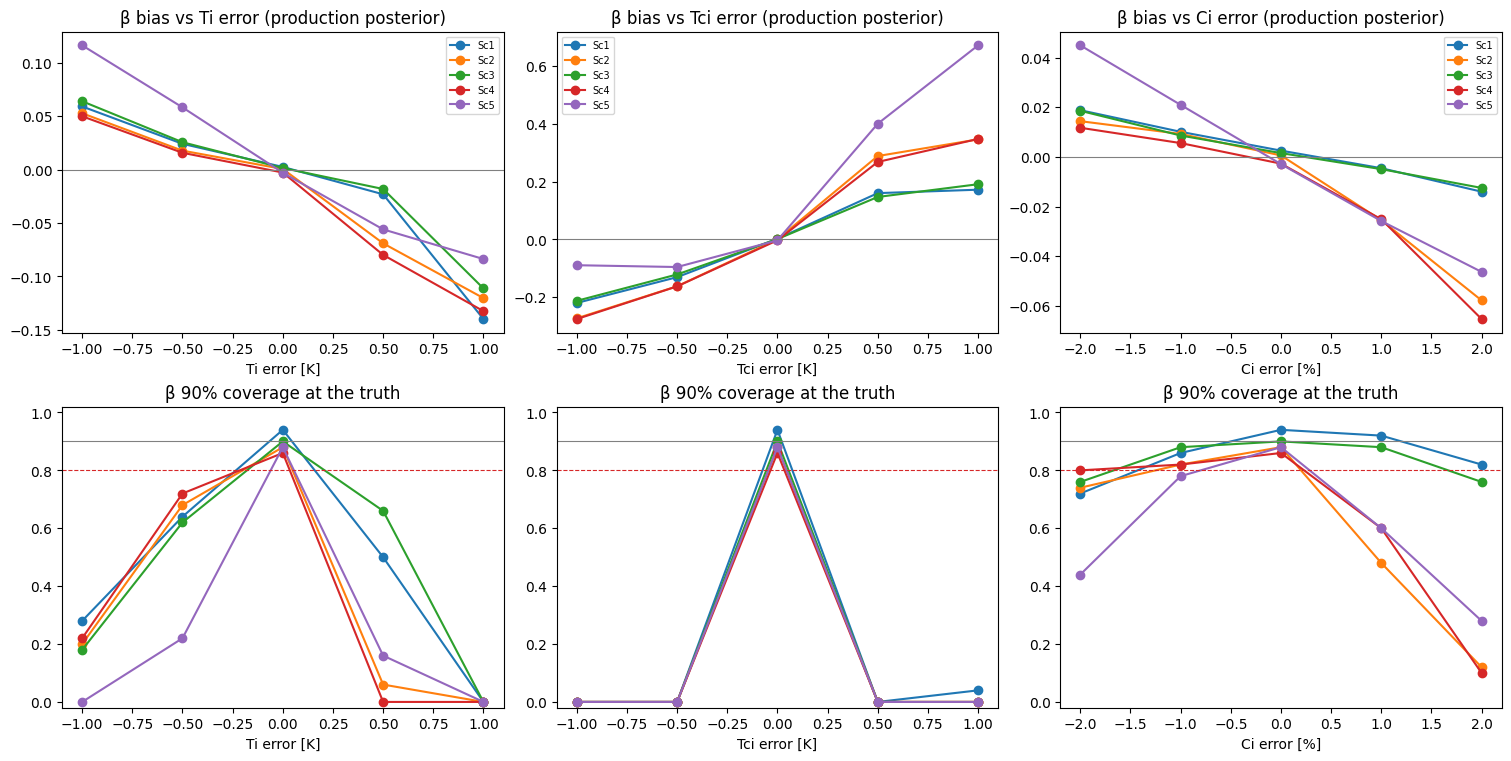

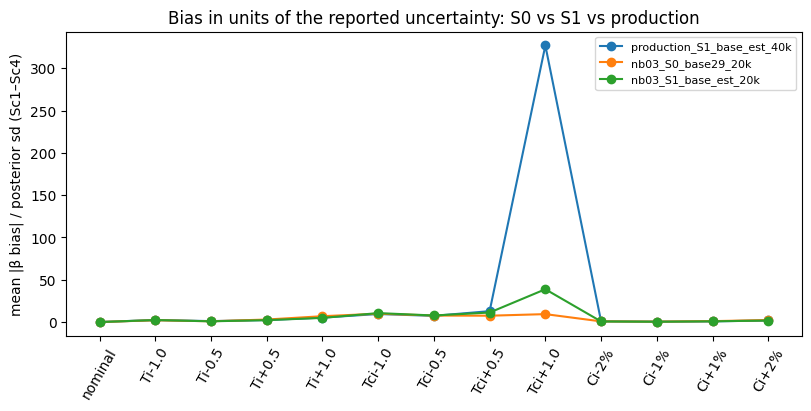

In [4]:
prod = [p for p in A.posterior.unique() if p.startswith("production_")][0]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for col, (fac, conds, xs, unit) in enumerate([("Ti", ["Ti-1.0", "Ti-0.5", "nominal", "Ti+0.5", "Ti+1.0"], [-1, -.5, 0, .5, 1], "K"),
                                              ("Tci", ["Tci-1.0", "Tci-0.5", "nominal", "Tci+0.5", "Tci+1.0"], [-1, -.5, 0, .5, 1], "K"),
                                              ("Ci", ["Ci-2%", "Ci-1%", "nominal", "Ci+1%", "Ci+2%"], [-2, -1, 0, 1, 2], "%")]):
    for sc in I.GATED + ["Sc5"]:
        d = A[(A.posterior == prod) & (A.short == sc)].set_index("condition").reindex(conds)
        axes[0, col].plot(xs, d.bias_b, "o-", label=sc)
        axes[1, col].plot(xs, d.cov90_truth_b, "o-", label=sc)
    axes[0, col].axhline(0, color="grey", lw=0.8)
    axes[0, col].set_title(f"β bias vs {fac} error (production posterior)"); axes[0, col].set_xlabel(f"{fac} error [{unit}]")
    axes[1, col].axhline(0.9, color="grey", lw=0.8); axes[1, col].axhline(0.8, color="C3", lw=0.8, ls="--")
    axes[1, col].set_ylim(-0.02, 1.02); axes[1, col].set_title("β 90% coverage at the truth"); axes[1, col].set_xlabel(f"{fac} error [{unit}]")
    axes[0, col].legend(fontsize=7)
fig.savefig(FIGS / f"{I.TAG}_A_beta_bias_coverage.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for p in A.posterior.unique():
    d = A[(A.posterior == p) & A.short.isin(I.GATED)].groupby("condition").z_bias_b.apply(lambda v: np.abs(v).mean())
    ax.plot(list(I.CONDITIONS), d.reindex(list(I.CONDITIONS)).values, "o-", label=p)
ax.set_ylabel("mean |β bias| / posterior sd (Sc1–Sc4)"); ax.tick_params(axis="x", rotation=60); ax.legend(fontsize=8)
ax.set_title("Bias in units of the reported uncertainty: S0 vs S1 vs production")
fig.savefig(FIGS / f"{I.TAG}_A_zbias_by_set.png", dpi=150); plt.show()

### 2b. Can the data flag the wrong inlet? Disagreement of the two β estimates
d = ln β̂_jac − ln β̂_rx per window, z-scored against a separate nominal calibration set (pooled
Sc1–Sc4). Detection rate at |z| > 3; the nominal row is the false-alarm rate.

In [5]:
al = I.stage_alarm_A()
display(al.pivot_table(index="condition", columns="scenario", values="shift_in_cal_sd").reindex(list(I.CONDITIONS)).round(2))
display(al.pivot_table(index="condition", columns="scenario", values="detect_rate_pooled").reindex(list(I.CONDITIONS)).round(2))

scenario,Sc1_closed_healthy,Sc2_closed_fouling,Sc3_closed_decay,Sc4_closed_combined,Sc5_closed_saturated
condition,,,,,
nominal,0.12,-0.60,0.30,-0.37,-1.80
Ti-1.0,-3.39,-2.92,-3.51,-2.79,-6.24
Ti-0.5,-1.40,-1.24,-1.39,-1.03,-4.16
Ti+0.5,1.02,0.02,1.46,0.02,0.91
Ti+1.0,1.44,1.81,1.94,1.81,4.16
Tci-1.0,-3.06,-7.62,-2.62,-6.99,-81.15
Tci-0.5,-1.56,-4.52,-1.24,-4.06,-81.14
Tci+0.5,2.04,5.20,2.03,4.66,12.39
Tci+1.0,4.29,12.57,4.00,11.59,19.23


scenario,Sc1_closed_healthy,Sc2_closed_fouling,Sc3_closed_decay,Sc4_closed_combined,Sc5_closed_saturated
condition,,,,,
nominal,0.00,0.00,0.00,0.00,0.12
Ti-1.0,0.68,0.50,0.72,0.38,1.00
Ti-0.5,0.04,0.02,0.04,0.02,0.86
Ti+0.5,0.00,0.00,0.06,0.00,0.04
Ti+1.0,0.02,0.08,0.08,0.10,0.84
Tci-1.0,0.60,0.98,0.30,0.96,1.00
Tci-0.5,0.00,0.82,0.00,0.80,1.00
Tci+0.5,0.16,0.90,0.16,0.84,1.00
Tci+1.0,0.80,1.00,0.82,1.00,1.00


## 3. Decision (pre-set rule)

In [6]:
decA = I.stage_decide_A()
RUN_B = decA["run_part_B"] or FORCE_B
print("Part B will run" if RUN_B else "Part B not needed (set FORCE_B = True to run it for the SI)")

NOT robust: 18 violations -> Part B
condition scenario  cov90_b  class_acc  acc_drop  bias_b  z_bias_b
   Ti-0.5      Sc1     0.64       1.00      0.00   0.024     1.298
   Ti-0.5      Sc2     0.68       0.96      0.02   0.018     1.189
   Ti-0.5      Sc3     0.62       1.00      0.00   0.026     1.299
   Ti-0.5      Sc4     0.72       0.86      0.02   0.016     1.049
   Ti+0.5      Sc1     0.50       1.00      0.00  -0.023    -1.648
   Ti+0.5      Sc2     0.06       0.98      0.00  -0.069    -3.112
   Ti+0.5      Sc3     0.66       1.00      0.00  -0.018    -1.338
   Ti+0.5      Sc4     0.00       0.86      0.02  -0.080    -3.605
  Tci-0.5      Sc1     0.00       0.10      0.90  -0.130    -8.568
  Tci-0.5      Sc2     0.00       0.88      0.10  -0.162    -6.559
  Tci-0.5      Sc3     0.00       0.12      0.88  -0.121    -7.794
  Tci-0.5      Sc4     0.00       0.98     -0.10  -0.162    -6.727
  Tci+0.5      Sc1     0.00       1.00      0.00   0.160    10.941
  Tci+0.5      Sc2     0.0

## 4. Part B — robust training with the inlet as a nuisance (runs only if needed)
Nominal vs robust S1 posteriors at 40k × 3 seeds (same θ draws and seeds). The price of robustness
is a wider β posterior; the gain is coverage under inlet errors.

In [7]:
if RUN_B:
    I.stage_bank_B(); I.stage_train_B(THREADS); I.stage_eval_B()
    Bm = pd.read_csv(R / f"{I.TAG}_B_metrics.csv"); Bm["short"] = Bm.scenario.str.split("_").str[0]
    for k in ("bias_b", "sd_b", "cov90_truth_b", "class_acc"):
        print(k)
        display(Bm.pivot_table(index=["posterior", "condition"], columns="short", values=k)
                .reindex(list(I.CONDITIONS), level=1).round(3))
    display(pd.read_csv(R / f"{I.TAG}_B_sbc.csv")[["posterior", "sbc_inlet", "ks_p_a_interior", "ks_p_b_interior",
                                                   "tarp_ks_p", "cov90_a", "cov90_b", "rmse_norm"]].round(4))
else:
    print("skipped")
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

nominal 0 43s


nominal 1 43s


nominal 2 43s


nominal 3 44s


nominal 4 43s


nominal 5 43s


... (38 outputs left out)

class_acc


short                                     Sc1   Sc2   Sc3   Sc4   Sc5
posterior                     condition                              
B_nominal_S1_base_est_40k_ens nominal    1.00  0.98  1.00  0.90  1.00
                              Ti-1.0     0.98  0.44  1.00  0.58  0.98
                              Ti-0.5     1.00  0.92  1.00  0.86  0.98
                              Ti+0.5     1.00  1.00  1.00  0.86  1.00
                              Ti+1.0     0.04  1.00  0.40  0.76  1.00
                              Tci-1.0    0.00  0.80  0.00  1.00  0.08
                              Tci-0.5    0.10  0.94  0.12  0.96  0.18
                              Tci+0.5    1.00  0.00  1.00  0.00  0.84
                              Tci+1.0    0.90  0.04  0.98  0.00  0.00
                              Ci-2%      1.00  0.98  1.00  0.84  1.00
                              Ci-1%      1.00  0.98  1.00  0.88  1.00
                              Ci+1%      1.00  0.98  1.00  0.88  1.00
                              Ci+2%      1.00  0.98  1.00  0.90  1.00
B_robust_S1_base_est_40k_ens  nominal    1.00  0.66  0.98  0.66  1.00
                              Ti-1.0     1.00  0.36  1.00  0.24  1.00
                              Ti-0.5     1.00  0.52  1.00  0.44  1.00
                              Ti+0.5     0.98  1.00  0.92  0.88  1.00
                              Ti+1.0     0.00  0.98  0.08  0.86  1.00
                              Tci-1.0    0.88  0.96  0.76  0.82  1.00
                              Tci-0.5    0.96  0.80  0.92  0.68  1.00
                              Tci+0.5    1.00  0.50  0.98  0.52  1.00
                              Tci+1.0    1.00  0.62  0.98  0.40  1.00
                              Ci-2%      1.00  0.56  1.00  0.38  1.00
                              Ci-1%      1.00  0.50  1.00  0.42  1.00
                              Ci+1%      0.98  0.96  0.96  0.78  1.00
                              Ci+2%      1.00  0.96  0.94  0.92  1.00

,posterior,sbc_inlet,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,cov90_a,cov90_b,rmse_norm
0,B_nominal_S1_base_est_40k_ens,nominal,0.0713,0.1977,0.3227,0.899,0.909,0.0375
1,B_nominal_S1_base_est_40k_ens,robust,0.0000,0.0000,0.0000,0.723,0.161,0.1969
2,B_robust_S1_base_est_40k_ens,nominal,0.0513,0.0000,0.0000,0.912,0.958,0.0539
3,B_robust_S1_base_est_40k_ens,robust,0.0641,0.0929,0.8109,0.904,0.888,0.0813


notebook wall time 31.9 min


## 5. Interpretation (N3 + P2 + S1, deployed 40k ensemble) — written 2026-11-09

**Result.** The production posterior is **not robust to realistic inlet errors, and the failure is silent**: the pre-set rule fails (18 of the 24 gated cells violate it; β coverage is ≥ 0.80 in only 6 of 24; only Ci −1% passes in all four scenarios), and the posterior's width does not respond (mean β sd 0.014 at the nominal inlet and 0.015–0.020 at the six gated conditions; 0.003–0.027 at the stress levels), so it is confident and wrong. The dominant sensitivity is to the **coolant inlet temperature Tci**, not to the feed. Marginalising the inlet in training (Part B) restores coverage at a price of about five times the β sd. This is the storyline's fourth source of silent failure (inlet conditions, after the control law, the warm start and the sensor model), it adds a sensor-specification message (β from T, Tc and Qc alone needs an accurate Tci), and it supplies a checklist item. Nothing in production was changed, and Part B is reported, not adopted (a user decision).

**1. Sensitivity (section 1, deterministic).** The two β estimators read different inlet quantities. The reactor-balance estimate β̂_rx moves with the feed temperature Ti and the feed concentration Ci: ln β̂_rx changes by +0.14 / −0.13 for Ti −0.5 / +0.5 K (+0.31 / −0.24 to −0.28 at ∓1 K) and by ∓5.4% for Ci ±1%. The jacket-balance estimate β̂_jac moves only with Tci, and strongly, because the coolant temperature rise Tc − Tci is only a few kelvin: ln β̂_jac changes by −0.12 to −0.31 for Tci −0.5 K and +0.14 to +0.46 for +0.5 K over Sc1–Sc4 (largest for the fouled scenarios; up to +1.3 for +1 K at Sc2). The α estimate is touched only by Ci, one for one (∓1.0% for ±1%), which is a quarter of the α sd (0.04). Ti and Tci do not enter α̂.

**2. Production posterior (Part A; pooled Sc1–Sc4, 50 windows per scenario).** β bias (in own posterior sd), 90% coverage, class accuracy (nominal: 0.90 and 0.96): Ti −0.5 K: +0.021 (1.2 sd), 0.67, 0.95; Ti +0.5 K: −0.048 (2.4 sd), 0.30, 0.96; **Tci −0.5 K: −0.144 (7.4 sd), 0.00, 0.52; Tci +0.5 K: +0.216 (13.0 sd), 0.00, 0.50**; Ci −1%: +0.008 (0.6 sd), 0.84, 0.96; Ci +1%: −0.015 (0.9 sd), 0.72, 0.97. Class accuracy survives the Ti and Ci errors (their β bias, ≤ 0.05, is smaller than the distance to the 0.90 threshold) but collapses for Tci (e.g. Sc2 and Sc4 at Tci +0.5 K: 0.00; Sc1 and Sc3 at Tci −0.5 K: 0.10–0.12, healthy and decay called fouling or combined): the precision claim fails for all three inlet quantities, the diagnosis only for Tci. The posterior does not widen (above), hence silent; at Tci +1 K its sd even shrinks to 0.003.
*Role of saturation (script `logs/34_N3_saturation_fractions.py`, raw windows of Part A).* The plant has a small cooling margin: the β = 0.85 scenarios (Sc2, Sc4) sit near the jacket-capacity limit (β ≈ 0.775), so a **+0.5 K feed error already puts 59% (Sc2) and 56% (Sc4) of the samples at Qc ≥ 395 L/min** (+1.0 K: 97% for both, and 23.5% even for the healthy plant; Ci +2%: 37% and 33%); in that regime the posterior reads the loss of cooling capacity as fouling and β̂ is biased low (−0.07 and −0.08 at Ti +0.5 K, coverage 0.06 and 0.00). Saturation amplifies the failure but is not its cause: Ti −0.5 K saturates nothing (0% of samples) and still gives coverage 0.62–0.72 (bias +0.016 to +0.026), Ti +0.5 K at Sc1 and Sc3 (0% saturated) coverage 0.50 and 0.66, and the **Tci biases are not a saturation effect** (0–1.1% of the samples at the limit at ±0.5 K, z up to 17).

**3. S0 against S1 (same windows and conditions, notebook 03 §10b ensembles at 20k, 3 seeds each).** Neither set is robust, and the explicit plug-in estimators of S1, which hard-code the nominal inlet, did **not** make it more fragile: S0 is as sensitive (the 29 summaries carry the nominal inlet implicitly through the learned map). Pooled β bias, S0 against S1: Ti +0.5 K −0.068 against −0.048, Ti +1.0 K −0.180 against −0.126, Ci +2% −0.051 against −0.037, Tci −0.5 K −0.140 against −0.143, Tci +0.5 K +0.148 against +0.205 (S1 about 40% larger, the only direction in which S1 is worse); class accuracy at Tci ±0.5 K is 0.50–0.53 for both. The Tci problem is a property of the plant's identifiability (Tc − Tci is small), not of the estimator. (The production ensemble is at 40k, the S0 and S1 comparison at 20k; the production S1 and the 20k S1 behave alike.)

**4. Alarm (section 2b: d = ln β̂_jac − ln β̂_rx, |z| > 3 against a nominal calibration set).** False-alarm rate at the nominal inlet 0.00 (pooled; 0.12 for the saturated Sc5). It detects the errors that hurt most, partially: Tci ±0.5 K in 0.40 (−) and 0.52 (+) of the windows over Sc1–Sc4, but unevenly (0.80–0.90 for the fouled Sc2 and Sc4, 0.00–0.16 for the healthy and decay Sc1 and Sc3, where the bias is also 9–11 sd); Tci ±1 K 0.71 and 0.90. It does **not** detect the feed errors: Ti ±0.5 K 0.02–0.03 (the shift is 1–1.5 calibration sd), Ti −1.0 K 0.57 and Ti +1.0 K 0.07, Ci ±1% and ±2% about 0.00. It responds only where an inlet error moves the two estimators apart (Tci moves β̂_jac alone; Ti and Ci move β̂_rx alone, but its calibration spread is larger). A partial, data-driven misspecification check that costs nothing, for the checklist; not a safeguard on its own.

**5. Part B (robust training; reported, not adopted).** Two S1 ensembles at 40k × 3 seeds with the same θ draws: "nominal" (inlet fixed) and "robust" (Ti and Tci ~ N(297, 0.5²) K, Ci ×(1 + N(0, 0.01²)) per sample). SBC with the inlet drawn from the realistic distribution: the nominal-trained posterior fails (β marginal KS p 0.000, TARP deviation 0.365, β coverage 0.161, normalised RMSE 0.197), the robust-trained one is calibrated (β KS p 0.76, interior 0.093, TARP KS p 0.81, deviation 0.018, coverage 0.888, RMSE 0.081). With the nominal inlet the reverse holds: the nominal-trained posterior is calibrated (β KS 0.31, TARP KS 0.32, coverage 0.909, RMSE 0.0375) and the robust-trained is over-conservative (β KS 0.000, coverage 0.958, RMSE 0.054). On the Part A conditions the robust-trained posterior has β coverage 0.93–0.99 at the realistic levels (Tci ±0.5 K: 0.97 and 0.95 with bias −0.010 and +0.039; Ti ±0.5 K: 0.93 and 0.99; Ci ±1%: 0.96 and 0.98) and 0.87–0.98 at the stress levels, except Ti +1.0 K (coverage 0.41, bias −0.19: saturation). **The price: β sd 0.015 → 0.07–0.11 (0.079 pooled at the nominal inlet, about five times), class accuracy at the nominal inlet 0.97 → 0.82**; α is unaffected (sd 0.036). The data cannot separate β from a ±0.5 K inlet error, so marginalising the inlet gives an honest, much wider β; the robust posterior is calibrated only for the inlet distribution it was trained on. Adopting it is the user's decision.

**6. Checklist item and the sensor-specification message.** *Measure or marginalise the inlet temperatures:* a bias below one posterior sd (0.015 in β) needs Tci known to about 0.04 K, Ti to about 0.15 K for positive errors (0.35 K for negative ones; the response is asymmetric near the valve limit) and Ci to about 1% (linear extrapolation from the ±0.5 K and ±1% runs, not separately simulated); otherwise marginalise them and accept a β sd of about 0.08. β (fouling) is diagnosable from T, Tc and Qc alone *if* the inlet temperatures are known (Tci above all); for α the feed concentration needs 2% accuracy at most. The deployed posterior and the claims about β precision hold for the nominal inlet only.

*Limitations:* one inlet factor at a time, 50 windows per scenario and condition (the standard error of a coverage fraction is 0.04–0.07), Part B with 3 seeds, feed flow Q not perturbed (a module constant of the physics).
